# 08 — FX mean restrictions, covariance stability and robustness

Compare the equity-only FX-pricing adaptation with the supplied paper's **currency-mean pricing
restriction**, then assess a simpler grouped covariance model. Run matched inflation-level and
post-floating-period sensitivities and inspect score influence without deleting time steps.

Run notebook 07 first, then **Run All** in the existing Miniconda **base** kernel. The main comparison
keeps its **321 frozen months and identical five observed series**. All input files are read locally.
The reusable likelihood/uncertainty implementation is in [pricing_robustness.py](pricing_robustness.py),
next to this notebook. Earlier notebooks and outputs are not edited.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/07_time_varying_currency/fixed_2026-11-13/2000-01_2026-09/var6_xd7a542e8"
COVARIANCE_MODELS=["scalar","grouped"]
START_DYNAMICS=[(.05,.90),(.10,.75)]
MAX_ITER=1800
TEST_LAGS=12
SE_STEP_TOL=.01
RUN_SENSITIVITIES=True
POST_FLOAT_START="2008-03"
REUSE_FITS=True
MODEL_VERSION="fx_mean_covariance_audit_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm,chi2
from packaging.version import Version
sm_version=importlib.metadata.version("statsmodels")
if Version(sm_version)<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0, then restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=sm_version:
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as model
importlib.reload(model)
engine_sha256=hashlib.sha256((ROOT/"pricing_robustness.py").read_bytes()).hexdigest()
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
print("Python:",sys.executable);print("Packages:",versions)
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",50)
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
if not COVARIANCE_MODELS or any(c not in ["scalar","grouped"] for c in COVARIANCE_MODELS) or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS):
    raise ValueError("Choose scalar and/or grouped covariance, without duplicates.")
COVARIANCE_MODELS=[c for c in ["scalar","grouped"] if c in COVARIANCE_MODELS]
source=ROOT/SNAPSHOT;baseline=ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text())
raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip")
data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous working months.")
baseline_hashes={}
def upstream_bytes(name):
    content=(baseline/name).read_bytes();baseline_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1])):
    raise ValueError("The notebook 07 sample differs from the sealed working data.")
for filename,key in [("ecb_fx.csv","raw_ecb_sha256"),("fred.csv","raw_fred_sha256"),("eurostat_hicp.json","raw_hicp_sha256")]:
    digest=hashlib.sha256((source/"raw"/filename).read_bytes()).hexdigest()
    if digest!=manifest["sources"][filename]["sha256"] or digest!=prior[key]:raise ValueError("Upstream/raw provenance mismatch.")
spec=prior["instrument_specification"]
if spec["HUF_inflation"]!="change" or spec["other_inflation"]!="level":
    raise ValueError("This audit expects notebook 07's documented change/level primary specification.")
FX_NAMES={"USD":["HUF","EUR"],"EUR":["HUF","USD"]}
normalizers=pd.read_csv(BytesIO(upstream_bytes("instrument_normalizers.csv")),index_col=[0,1,2],float_precision="round_trip").sort_index()
quality=pd.read_csv(BytesIO(upstream_bytes("conditioning_quality_flags.csv")),index_col=[0,1])
inflation=pd.read_csv(BytesIO(upstream_bytes("inflation_reconstruction.csv")),index_col=0,float_precision="round_trip")
inflation.index=pd.PeriodIndex(inflation.index,freq="M")
np.testing.assert_allclose(inflation["level_US_HU_lag2_pp"],data["inflation_gap_usd_lag2_pp"],atol=1e-12,rtol=0)
np.testing.assert_allclose(inflation["level_EA_HU_lag2_pp"],data["inflation_gap_eur_lag2_pp"],atol=1e-12,rtol=0)
for gap in ["US_HU","EA_HU","US_EA"]:
    np.testing.assert_allclose(inflation[f"change_{gap}_lag2_pp"].iloc[1:],inflation[f"level_{gap}_lag2_pp"].diff().iloc[1:],atol=1e-12,rtol=0)
features,price_designs,samples={}, {}, {}
for currency in ["USD","EUR"]:
    features[currency],price_designs[currency]={},{}
    for label in ["W","H","O"]:
        z=pd.read_csv(BytesIO(upstream_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Upstream design months differ.")
        stats=normalizers.loc[(currency,label)].reindex(z.columns[1:])
        frame=pd.DataFrame(z.iloc[:,1:].to_numpy()*stats["sd"].to_numpy()+stats["mean"].to_numpy(),index=data.index,columns=z.columns[1:])
        for name in spec["world"]:np.testing.assert_allclose(frame[name],data[name],atol=1e-12,rtol=0)
        for name in frame.columns:
            if name.startswith("HUF_inflation"):
                gap="US_HU" if currency=="USD" else "EA_HU"
                np.testing.assert_allclose(frame[name],inflation[f"change_{gap}_lag2_pp"],atol=1e-12,rtol=0)
            if name.startswith("other_inflation"):
                np.testing.assert_allclose(frame[name],(1 if currency=="USD" else -1)*inflation["level_US_EA_lag2_pp"],atol=1e-12,rtol=0)
            if name=="floating_regime_known":np.testing.assert_allclose(frame[name],data[name],atol=1e-12,rtol=0)
        features[currency][label],price_designs[currency][label]=frame,z.to_numpy()
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
ecb=pd.read_csv(source/"raw"/"ecb_fx.csv",usecols=["TIME_PERIOD","CURRENCY","OBS_VALUE"],float_precision="round_trip")
ecb["TIME_PERIOD"]=pd.to_datetime(ecb["TIME_PERIOD"])
ecb=ecb.pivot(index="TIME_PERIOD",columns="CURRENCY",values="OBS_VALUE").sort_index()
ecb=ecb.groupby(ecb.index.to_period("M")).last()
fx_usd=pd.DataFrame({"H":-np.log(ecb["HUF"]/ecb["USD"]).diff(),"O":np.log(ecb["USD"]).diff()})*100
fx_history={"USD":fx_usd,"EUR":pd.DataFrame({"H":fx_usd["H"]-fx_usd["O"],"O":-fx_usd["O"]})}
for c in ["USD","EUR"]:np.testing.assert_allclose(fx_history[c].loc[data.index],samples[c][:,3:],atol=1e-11,rtol=0)
OUT=ROOT/"output"/"08_specification_audit"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/f"spec_{hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:8]}"
OUT.mkdir(parents=True,exist_ok=True)
display(pd.DataFrame({"first":[str(data.index[0])],"last":[str(data.index[-1])],"main_months":[len(data)],"upstream":["07 verified conditioners"]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,main_months,upstream
0,2000-01,2026-09,321,07 verified conditioners


## 1. Specify the comparison before fitting

For $j\in\{HUF,other\ FX\}$, the supplied draft's
[equation (7)](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf)
implies

$$\boxed{E_{t-1}[f_{j,t}]=\lambda_{W,t}H_{jW,t}+\lambda_{H,t}H_{jH,t}+\lambda_{O,t}H_{jO,t}.}$$

Use the same three priced components in all five mean equations; local variance terms still enter
only the US and Hungarian equity equations. Apply this as an empirical restriction on our observed
**spot log changes**, following the draft's measurement choice. No deposit/forward returns or HUF
cash series are manufactured. Public-data proxies, the two-FX basis and our audited inflation
transformations remain adaptations; matching equation (7) does not make every specification identical.

| Mean model | FX mean | Free FX forecasting coefficients |
|---|---|---:|
| `var6` | Existing unrestricted VAR(6), without FX-mean pricing restriction | 26 |
| `paper` | Equation (7), no extra FX mean terms | 0 |
| `paper_var1` | Equation (7) + unrestricted intercept / VAR(1) correction | 6 |

`paper` nests inside `paper_var1` when the six correction coefficients are zero. Test that restriction
with the full robust covariance matrix. `var6` and `paper` are non-nested: compare descriptive
AIC/BIC on **identical five-series samples**, without an ordinary LR chi-square test.

For covariance, compare scalar BEKK with **grouped diagonal BEKK**: World/US share one pair of
dynamics, Hungary has another, and the two FX innovations share a third. The free $CC'$ intercept
and stationary initial innovation covariance remain as before. This adds four dynamic parameters to
scalar, versus eight under the earlier unrestricted diagonal dynamics. The grouping is economic and
fixed before inspecting results. Notebook 07's boundary-sensitive diagonal fits remain audit records.

With the default 17 risk-price coefficients and 15 intercept coordinates, scalar/grouped parameter
counts are **60/64** (`var6`), **34/38** (`paper`), and **40/44** (`paper_var1`). World and currency
prices remain time-varying; local equity prices remain time-constant throughout this notebook.

In [2]:
def make_case(currency,mean_model,covariance_model,variant="full"):
    months=data.index if variant!="post_float" else data.index[data.index>=pd.Period(POST_FLOAT_START,freq="M")]
    if len(months)<120:raise ValueError("Use at least 120 months for the auxiliary fit.")
    frames={a:f.loc[months].copy() for a,f in features[currency].items()}
    if variant=="levels":
        gap="US_HU" if currency=="USD" else "EA_HU"
        old_name=[c for c in frames["H"] if c.startswith("HUF_inflation")][0]
        frames["H"]=frames["H"].rename(columns={old_name:"HUF_inflation_gap_level_lag2_pp"})
        frames["H"]["HUF_inflation_gap_level_lag2_pp"]=inflation.loc[months,f"level_{gap}_lag2_pp"]
    dropped={a:[c for c in f if f[c].nunique(dropna=False)<=1] for a,f in frames.items()}
    for a in frames:frames[a]=frames[a].drop(columns=dropped[a])
    if variant=="full":pdsg={a:z.copy() for a,z in price_designs[currency].items()}
    else:pdsg={a:np.c_[np.ones(len(months)),((f-f.mean())/f.std(ddof=1)).to_numpy()] for a,f in frames.items()}
    for z in pdsg.values():
        if not np.isfinite(z).all() or np.linalg.matrix_rank(z)!=z.shape[1]:raise ValueError("Invalid auxiliary price design.")
    y=samples[currency][data.index.isin(months)];scales=y.std(axis=0,ddof=1)
    lags=prior["FX_VAR_lags"] if mean_model=="var6" else (1 if mean_model=="paper_var1" else 0)
    if lags:
        x=np.c_[np.ones(len(months)),np.concatenate([(fx_history[currency]/scales[3:]).shift(j).loc[months].to_numpy() for j in range(1,lags+1)],axis=1)]
    else:x=np.empty((len(months),0))
    if not np.isfinite(y).all() or not np.isfinite(x).all():raise ValueError("Missing model data.")
    return {"id":f"{currency}_{mean_model}_{covariance_model}_{variant}","currency":currency,"mean_model":mean_model,
            "mode":"var" if mean_model=="var6" else "priced","covariance_model":covariance_model,"variant":variant,
            "dates":months,"y":y,"x":x,"pdesign":pdsg,"scales":scales,"frames":frames,"dropped":dropped}

def args(case):return (case["y"],case["x"],case["pdesign"],case["scales"],case["mode"],case["covariance_model"])

references,retired_rows={},[]
old_fit_table=pd.read_csv(BytesIO(upstream_bytes("fit_summary.csv")),index_col=[0,1,2],float_precision="round_trip")
for currency in ["USD","EUR"]:
    for covariance_model in ["scalar","diagonal"]:
        case=make_case(currency,"var6",covariance_model)
        name=f"{currency}_{covariance_model}_time_varying_fx"
        record=json.loads(upstream_bytes(f"fit_{name}.json"));theta=np.asarray(record["theta"],dtype=float)
        with np.load(BytesIO(upstream_bytes(f"parameters_{name}.npz")),allow_pickle=False) as arrays:
            saved={k:arrays[k].copy() for k in arrays.files}
        np.testing.assert_allclose(theta,saved["theta"],atol=0,rtol=0)
        f=model.filter_model(theta,*args(case))
        np.testing.assert_allclose(f["losses"].mean(),record["mean_nll"],atol=1e-10,rtol=0)
        for key,old_name in [("H","H"),("mu","mu"),("errors","residuals")]:np.testing.assert_allclose(f[key],saved[old_name],atol=1e-8,rtol=1e-10)
        if np.max(np.abs(f["scores"].mean(axis=0)))>=1e-4:raise ValueError("Legacy fit no longer validates.")
        case.update(theta=theta,filter=f,source="verified notebook 07")
        references[(currency,covariance_model)]=case
        if covariance_model=="diagonal":
            bounds=np.asarray(model.parameter_bounds(case["x"],case["pdesign"],covariance_model))
            distance=np.minimum(theta-bounds[:,0],bounds[:,1]-theta);j=int(np.argmin(distance))
            kk,gg,dd=model.layout(case["x"],case["pdesign"],covariance_model)
            if kk+gg<=j<kk+gg+15:
                ii,jj=list(zip(*model.TRI))[j-kk-gg]
                bound_name=f"normalised intercept Cholesky C[{ii+1},{jj+1}]"+(" log diagonal" if ii==jj else "")
            else:bound_name=f"parameter {j}"
            old=old_fit_table.loc[(currency,covariance_model,"time_varying_fx")]
            retired_rows.append({"perspective":currency,"status":"retained for audit; no new diagonal fits",
                "closest_parameter_position":j,"bound_parameter":bound_name,"value":theta[j],"distance_to_bound":distance[j],
                "Hessian_condition":old["Hessian_condition"],"inference_ready":bool(old["numerical_inference_ready"])})
retired=pd.DataFrame(retired_rows).set_index("perspective")
display(retired)
checks=[]
for currency in ["USD","EUR"]:
    for mean_model in ["var6","paper","paper_var1"]:
        for covariance_model in COVARIANCE_MODELS:
            c=make_case(currency,mean_model,covariance_model)
            theta=model.initial_theta(*args(c))
            for idx in model.price_indices(c["pdesign"]).values():theta[idx[1:]]=np.linspace(.1,-.08,len(idx)-1)
            if covariance_model=="grouped":theta[-6:]+=np.linspace(-.15,.15,6)
            sub={a:z[:35] for a,z in c["pdesign"].items()}
            aa=(c["y"][:35],c["x"][:35],sub,c["scales"],c["mode"],covariance_model)
            analytic=model.objective(theta,*aa)[1]
            numeric=model.numerical_gradient(lambda t:model.objective(t,*aa)[0],theta)
            np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
            checks.append({"perspective":currency,"mean":mean_model,"covariance":covariance_model,"gradient_error":np.max(np.abs(analytic-numeric))})
    pure,aug=make_case(currency,"paper","scalar"),make_case(currency,"paper_var1","scalar")
    theta=model.initial_theta(*args(pure));nested=model.change_mean(theta,pure["x"],aug["x"],pure["pdesign"])
    np.testing.assert_allclose(model.filter_model(theta,*args(pure))["losses"],model.filter_model(nested,*args(aug))["losses"],atol=1e-12,rtol=0)
    grouped=make_case(currency,"paper","grouped")
    np.testing.assert_allclose(model.filter_model(theta,*args(pure))["H"],model.filter_model(model.expand_scalar(theta,"grouped"),*args(grouped))["H"],atol=1e-12,rtol=0)
display(pd.DataFrame(checks))

,status,closest_parameter_position,bound_parameter,value,distance_to_bound,Hessian_condition,inference_ready
perspective,,,,,,,
USD,retained for audit; no new diagonal fits,57,"normalised intercept Cholesky C[5,5] log diagonal",-8.0,0.0,1.927384e+09,False
EUR,retained for audit; no new diagonal fits,57,"normalised intercept Cholesky C[5,5] log diagonal",-8.0,0.0,7.480284e+12,False


,perspective,mean,covariance,gradient_error
0,USD,var6,scalar,4.699121e-08
1,USD,var6,grouped,4.850148e-08
2,USD,paper,scalar,4.594815e-08
3,USD,paper,grouped,4.760245e-08
4,USD,paper_var1,scalar,4.704534e-08
5,USD,paper_var1,grouped,4.858434e-08
6,EUR,var6,scalar,6.739678e-08
7,EUR,var6,grouped,7.383490e-08
8,EUR,paper,scalar,6.612105e-08
9,EUR,paper,grouped,7.300118e-08


## 2. Fit the prespecified models and sensitivities

Reuse the verified scalar VAR(6) reference. Estimate the other main cells, with nested starts where
applicable. Cache fingerprints include the helper source, raw-data vintage, exact model arrays,
settings and runtime. A cached fit must reproduce its objective, bounds and gradient.

Two planned auxiliary fits use `paper`/scalar for both investors: **HUF inflation-gap levels** instead
of changes, and the **post-floating period from March 2008**. The latter retains a matched monthly
window and drops the now-constant regime dummy, recording that change. These are separate outputs;
all primary comparisons retain 321 months. Do not compare AIC across different sample windows.
The level-gap stationarity evidence remains inconclusive, so that sensitivity is exploratory.

In [3]:
fits,start_rows={},[]
plans=[make_case(c,m,v) for c in ["USD","EUR"] for m in ["var6","paper","paper_var1"] for v in COVARIANCE_MODELS]
if RUN_SENSITIVITIES:
    plans += [make_case(c,"paper","scalar",variant) for variant in ["levels","post_float"] for c in ["USD","EUR"]]
for case in plans:
    key=case["id"];print(key,flush=True)
    c,m,v,variant=case["currency"],case["mean_model"],case["covariance_model"],case["variant"]
    if m=="var6" and v=="scalar" and variant=="full":
        case.update(theta=references[(c,v)]["theta"],filter=references[(c,v)]["filter"],source="verified notebook 07")
        fits[key]=case;print("  verified upstream reference",flush=True);continue
    config={"model_version":MODEL_VERSION,"engine_sha256":engine_sha256,"source_sha256":manifest["exports"]["dataset.csv"],
        "case":key,"first":str(case["dates"][0]),"last":str(case["dates"][-1]),"n":len(case["dates"]),
        "mode":case["mode"],"groups":model.GROUPS[v],"dropped_columns":case["dropped"],
        "price_columns":{a:list(f.columns) for a,f in case["frames"].items()},"starts":START_DYNAMICS,"max_iter":MAX_ITER,
        "upstream_sha256":baseline_hashes["estimation_manifest.json"],"packages":versions,"python":platform.python_version()}
    payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+case["x"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O"])
    fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
    cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
    record=None;bounds=np.asarray(model.parameter_bounds(case["x"],case["pdesign"],v))
    candidate=np.asarray(cached["theta"],dtype=float) if cached else np.array([])
    usable=candidate.shape==(len(bounds),) and np.isfinite(candidate).all()
    if usable and cached.get("fingerprint")==fingerprint and (candidate>=bounds[:,0]).all() and (candidate<=bounds[:,1]).all():
        value,gradient=model.objective(candidate,*args(case))
        if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:record=cached;print("  verified cached fit",flush=True)
    starts=[model.initial_theta(*args(case),alpha=a,beta=b) for a,b in START_DYNAMICS];nested=[]
    scalar_key=f"{c}_{m}_scalar_{variant}"
    if v=="grouped" and scalar_key in fits:
        starts.insert(0,model.expand_scalar(fits[scalar_key]["theta"],v));nested.append(scalar_key)
    pure_key=f"{c}_paper_{v}_{variant}"
    if m=="paper_var1" and pure_key in fits:
        parent=fits[pure_key];starts.insert(0,model.change_mean(parent["theta"],parent["x"],case["x"],case["pdesign"]));nested.append(pure_key)
    var_key=f"{c}_var6_{v}_{variant}"
    if m=="paper" and var_key in fits:
        parent=fits[var_key];starts.insert(0,model.change_mean(parent["theta"],parent["x"],case["x"],case["pdesign"]))
    if usable:starts.insert(0,np.clip(candidate,bounds[:,0],bounds[:,1]))
    if record is None:
        best,runs=model.fit_starts(*args(case),starts,MAX_ITER)
        record={"fingerprint":fingerprint,"config":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
        path.write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
    theta=np.asarray(record["theta"],dtype=float);f=model.filter_model(theta,*args(case))
    for parent in nested:
        if f["losses"].sum()>fits[parent]["filter"]["losses"].sum()+1e-5:raise ValueError(f"Fit worse than nested {parent}.")
    case.update(theta=theta,filter=f,source="estimated here");fits[key]=case
    start_rows += [{"case":key,**r} for r in record["starts"]]
starts_table=pd.DataFrame(start_rows)
display(starts_table.drop(columns="message").round(7))

USD_var6_scalar_full


  verified upstream reference


USD_var6_grouped_full


  verified cached fit


USD_paper_scalar_full


  verified cached fit


... (23 outputs left out)

  verified cached fit


EUR_paper_scalar_post_float


  verified cached fit


,case,BFGS_success,iterations,max_abs_gradient,mean_nll,start,success
0,USD_var6_grouped_full,True,298,1.000000e-07,11.571611,1,True
1,USD_var6_grouped_full,True,307,5.000000e-07,11.571611,2,True
2,USD_var6_grouped_full,True,300,4.000000e-07,11.571611,3,True
3,USD_paper_scalar_full,True,239,1.200000e-06,11.586644,1,True
4,USD_paper_scalar_full,True,245,5.500000e-06,11.586644,2,True
5,USD_paper_scalar_full,True,243,2.200000e-06,11.586644,3,True
6,USD_paper_grouped_full,True,278,3.600000e-06,11.579462,1,True
7,USD_paper_grouped_full,True,220,6.400000e-06,11.579462,2,True
8,USD_paper_grouped_full,True,278,4.900000e-06,11.579462,3,True
9,USD_paper_grouped_full,True,262,6.500000e-06,11.579462,4,True


## 3. Regularity, restrictions and residual adequacy

Recalculate the full joint sandwich $A^{-1}BA^{-1}/T$. Numerical gates, two-step curvature/SE checks,
stationary AR corrections and nominal residual screens are unchanged. Test the six FX correction
coefficients jointly zero in `paper_var1`; test constant and zero FX prices separately. All tests remain
conditional on correctly specified moments, and are exploratory when diagnostics or instrument
assumptions remain uncertain. Read numerical readiness separately from statistical adequacy.

For grouped covariance, a four-restriction delta-method Wald test checks common shock and
persistence coefficients across the three groups, with all other parameters jointly estimated.

In [4]:
fit_rows,test_rows,coef_rows,residual_rows,cross_rows,premium_rows=[],[],[],[],[],[]
for key,case in fits.items():
    f,theta=case["filter"],case["theta"]
    inf=model.inference(theta,*args(case),filtered=f,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    labels=["World","US","Hungary"]+[f"{x} FX" for x in FX_NAMES[case["currency"]]]
    marginal,cross=model.diagnostics(f,labels,TEST_LAGS);case["marginal"],case["cross"]=marginal,cross
    residual_rows += [{"case":key,"series":name,**row.to_dict()} for name,row in marginal.iterrows()]
    cross_rows += [{"case":key,"pair":name,**row.to_dict()} for name,row in cross.iterrows()]
    ll=-f["losses"].sum();n=len(case["y"]);k,g,dyn=model.layout(case["x"],case["pdesign"],case["covariance_model"])
    groups=model.price_indices(case["pdesign"])
    restrictions=[("FX prices constant",np.r_[groups["H"][1:],groups["O"][1:]]),
        ("FX prices zero",np.r_[groups["H"],groups["O"]]),("Local equity prices zero",[1,2])]
    if case["mean_model"]=="paper_var1":restrictions.insert(0,("Paper FX mean restriction",np.arange(k,k+g)))
    for name,indices in restrictions:test_rows.append({"case":key,"test":name,**model.wald(theta,inf["covariance"],indices)})
    if case["covariance_model"]=="grouped":
        representatives=[0,2,3]
        aa,bb=f["alpha"][representatives],f["beta"][representatives]
        derivative_a=np.zeros((3,len(theta)));derivative_b=np.zeros_like(derivative_a)
        for group in range(3):
            u,v=len(theta)-6+2*group,len(theta)-5+2*group
            derivative_a[group,u],derivative_a[group,v]=aa[group]*(1-aa[group]),-aa[group]*bb[group]
            derivative_b[group,u],derivative_b[group,v]=-aa[group]*bb[group],bb[group]*(1-bb[group])
        restriction=np.r_[aa[1:]-aa[0],bb[1:]-bb[0]]
        J=np.r_[derivative_a[1:]-derivative_a[0],derivative_b[1:]-derivative_b[0]]
        variance=J@inf["covariance"]@J.T
        valid=inf["ready"] and np.linalg.eigvalsh(variance).min()>0 and np.linalg.cond(variance)<1e9
        statistic=restriction@np.linalg.solve(variance,restriction) if valid else np.nan
        test_rows.append({"case":key,"test":"Common covariance dynamics","Wald_statistic":statistic,"df":4,
                          "robust_p_value":chi2.sf(statistic,4) if valid else np.nan})

    for label,indices in groups.items():
        names=["intercept"]+list(case["frames"][label].columns)
        for j,name in zip(indices,names):
            value=model.PRICE_SCALE*theta[j];se=model.PRICE_SCALE*np.sqrt(inf["covariance"][j,j]) if inf["ready"] else np.nan
            coef_rows.append({"case":key,"risk":label,"term":name,"estimate":value,"robust_se":se,
                             "p_value":2*norm.sf(abs(value/se)) if inf["ready"] else np.nan,"ci95_low":value-1.96*se,"ci95_high":value+1.96*se})
    for j,label in [(1,"US local"),(2,"Hungary local")]:
        value=model.PRICE_SCALE*theta[j];se=model.PRICE_SCALE*np.sqrt(inf["covariance"][j,j]) if inf["ready"] else np.nan
        coef_rows.append({"case":key,"risk":label,"term":"intercept","estimate":value,"robust_se":se,
                         "p_value":2*norm.sf(abs(value/se)) if inf["ready"] else np.nan,"ci95_low":value-1.96*se,"ci95_high":value+1.96*se})
    H,p=f["H"],f["prices"]
    components=pd.DataFrame({"world":f["world_prices"]*H[:,2,0],"local":p[2]*H[:,2,2],
        "HUF_FX":f["fx_prices"][:,0]*H[:,2,3],"other_FX":f["fx_prices"][:,1]*H[:,2,4]},index=case["dates"])
    components["total"]=components.sum(axis=1)
    np.testing.assert_allclose(components["total"],f["mu"][:,2],atol=1e-10,rtol=0);case["components"]=components
    premium_rows += [{"case":key,"component":name,"mean_monthly_pct":v.mean(),"sd_monthly_pct":v.std(ddof=1)} for name,v in components.items()]
    fit_rows.append({"case":key,"perspective":case["currency"],"mean_model":case["mean_model"],"covariance":case["covariance_model"],"variant":case["variant"],
        "n":n,"parameters":len(theta),"loglik":ll,"AIC":-2*ll+2*len(theta),"BIC":-2*ll+np.log(n)*len(theta),
        "gradient":np.max(np.abs(f["scores"].mean(axis=0))),"Hessian_condition":inf["Hessian_condition"],
        "price_SE_step_difference":inf["price_SE_step_difference"],"near_bound":inf["near_bound"],"inference_ready":inf["ready"],"reason":inf["reason"],
        "FX_AR_radius":inf["FX_AR_radius"],"mean_flags":int(marginal["LB_z_p"].lt(.05).sum()),
        "variance_flags":int((marginal["LB_z_squared_p"].lt(.05)|marginal["ARCH_LM_p"].lt(.05)).sum()),"cross_flags":int(cross["LB_product_p"].lt(.05).sum())})
fit_table=pd.DataFrame(fit_rows).set_index("case")
tests=pd.DataFrame(test_rows).set_index(["case","test"])
coefficients=pd.DataFrame(coef_rows).set_index(["case","risk","term"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"])
cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
premia=pd.DataFrame(premium_rows).set_index(["case","component"])
main=fit_table[fit_table["variant"]=="full"].copy()
for currency in ["USD","EUR"]:
    idx=main["perspective"].eq(currency)
    main.loc[idx,"AIC_from_best"]=main.loc[idx,"AIC"]-main.loc[idx,"AIC"].min()
    main.loc[idx,"BIC_from_best"]=main.loc[idx,"BIC"]-main.loc[idx,"BIC"].min()
main["FX_mean_restriction_p"]=[tests.loc[(key,"Paper FX mean restriction"),"robust_p_value"] if fits[key]["mean_model"]=="paper_var1" else np.nan for key in main.index]
main["common_dynamics_p"]=[tests.loc[(key,"Common covariance dynamics"),"robust_p_value"] if fits[key]["covariance_model"]=="grouped" else np.nan for key in main.index]
main["FX_constancy_p"]=[tests.loc[(key,"FX prices constant"),"robust_p_value"] for key in main.index]
main["FX_zero_p"]=[tests.loc[(key,"FX prices zero"),"robust_p_value"] for key in main.index]
display(main[["perspective","mean_model","covariance","parameters","AIC_from_best","BIC_from_best","common_dynamics_p","FX_mean_restriction_p","FX_constancy_p","FX_zero_p","mean_flags","variance_flags","cross_flags","inference_ready","reason"]].round(4))
display(fit_table[fit_table["variant"]!="full"][["perspective","variant","n","parameters","mean_flags","variance_flags","cross_flags","inference_ready","reason"]])

,perspective,mean_model,covariance,parameters,AIC_from_best,BIC_from_best,common_dynamics_p,FX_mean_restriction_p,FX_constancy_p,FX_zero_p,mean_flags,variance_flags,cross_flags,inference_ready,reason
case,,,,,,,,,,,,,,,
USD_var6_scalar_full,USD,var6,scalar,60,47.7044,145.7618,NaN,NaN,0.3306,0.4424,0,4,2,True,numerically ready
USD_var6_grouped_full,USD,var6,grouped,64,50.3488,163.4920,0.2355,NaN,0.3595,0.4595,0,3,3,True,numerically ready
USD_paper_scalar_full,USD,paper,scalar,34,0.0000,0.0000,NaN,NaN,0.0006,0.0011,0,4,0,True,numerically ready
USD_paper_grouped_full,USD,paper,grouped,38,3.3892,18.4750,0.1774,NaN,0.0021,0.0046,0,2,0,True,numerically ready
USD_paper_var1_scalar_full,USD,paper_var1,scalar,40,4.0335,26.6622,NaN,0.3403,0.0018,0.0011,0,4,1,True,numerically ready
USD_paper_var1_grouped_full,USD,paper_var1,grouped,44,7.4685,45.1829,0.1419,0.3632,0.0030,0.0047,0,2,1,True,numerically ready
EUR_var6_scalar_full,EUR,var6,scalar,60,56.8170,154.8744,NaN,NaN,0.0917,0.1097,0,1,1,True,numerically ready
EUR_var6_grouped_full,EUR,var6,grouped,64,57.3542,170.4975,0.1062,NaN,0.1995,0.1069,0,1,1,True,numerically ready
EUR_paper_scalar_full,EUR,paper,scalar,34,0.0000,0.0000,NaN,NaN,0.0000,0.0000,0,1,0,True,numerically ready


,perspective,variant,n,parameters,mean_flags,variance_flags,cross_flags,inference_ready,reason
case,,,,,,,,,
USD_paper_scalar_levels,USD,levels,321,34,0,3,1,True,numerically ready
EUR_paper_scalar_levels,EUR,levels,321,34,1,3,0,True,numerically ready
USD_paper_scalar_post_float,USD,post_float,223,33,0,2,1,True,numerically ready
EUR_paper_scalar_post_float,EUR,post_float,223,33,0,1,0,True,numerically ready


## 4. Influence without breaking the monthly recursion

For regular main fits, approximate the change from removing one **likelihood term**, leaving the full
observed return path intact: $\Delta\theta_t\approx A^{-1}g_t/T$, where $g_t$ is its loss score and
$A$ the average-loss Hessian. Rank the largest price-coefficient shift relative to its marginal SE.
This is a first-order influence screen, not an exact deletion/refit or a reconstruction of missing CPI.
Flag the existing carried-inflation conditioners and prespecified crisis periods. The auxiliary
post-floating refit provides a separate matched-window check; its AIC is not pooled with full-sample AIC.

,case,month,max_price_shift_in_SE,carried_conditioner,crisis_block,rank_in_case
311,USD_var6_scalar_full,2025-12,0.0448,True,,248.0
312,USD_var6_scalar_full,2026-01,0.0824,True,,150.0
632,USD_var6_grouped_full,2025-12,0.0332,True,,276.0
633,USD_var6_grouped_full,2026-01,0.0891,True,,136.0
953,USD_paper_scalar_full,2025-12,0.0507,True,,250.0
954,USD_paper_scalar_full,2026-01,0.0640,True,,205.0
1274,USD_paper_grouped_full,2025-12,0.0501,True,,247.0
1275,USD_paper_grouped_full,2026-01,0.0935,True,,128.0
1595,USD_paper_var1_scalar_full,2025-12,0.0243,True,,312.0
1596,USD_paper_var1_scalar_full,2026-01,0.0890,True,,132.0


,case,month,max_price_shift_in_SE,carried_conditioner,crisis_block,rank_in_case
2996,EUR_paper_grouped_full,2008-12,0.7397,False,2008-2009,1.0
3000,EUR_paper_grouped_full,2009-04,0.6081,False,2008-2009,2.0
2997,EUR_paper_grouped_full,2009-01,0.5657,False,2008-2009,3.0
2675,EUR_paper_scalar_full,2008-12,0.7296,False,2008-2009,1.0
2676,EUR_paper_scalar_full,2009-01,0.6030,False,2008-2009,2.0
2679,EUR_paper_scalar_full,2009-04,0.5980,False,2008-2009,3.0
3638,EUR_paper_var1_grouped_full,2008-12,0.7067,False,2008-2009,1.0
3642,EUR_paper_var1_grouped_full,2009-04,0.6326,False,2008-2009,2.0
3639,EUR_paper_var1_grouped_full,2009-01,0.5363,False,2008-2009,3.0
3317,EUR_paper_var1_scalar_full,2008-12,0.7171,False,2008-2009,1.0


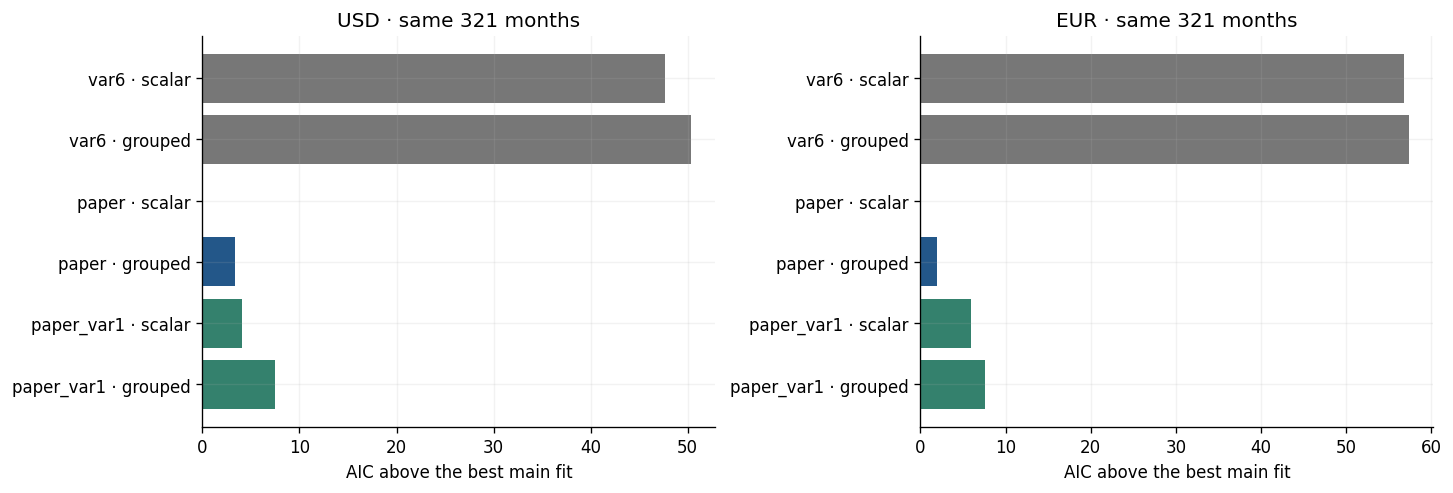

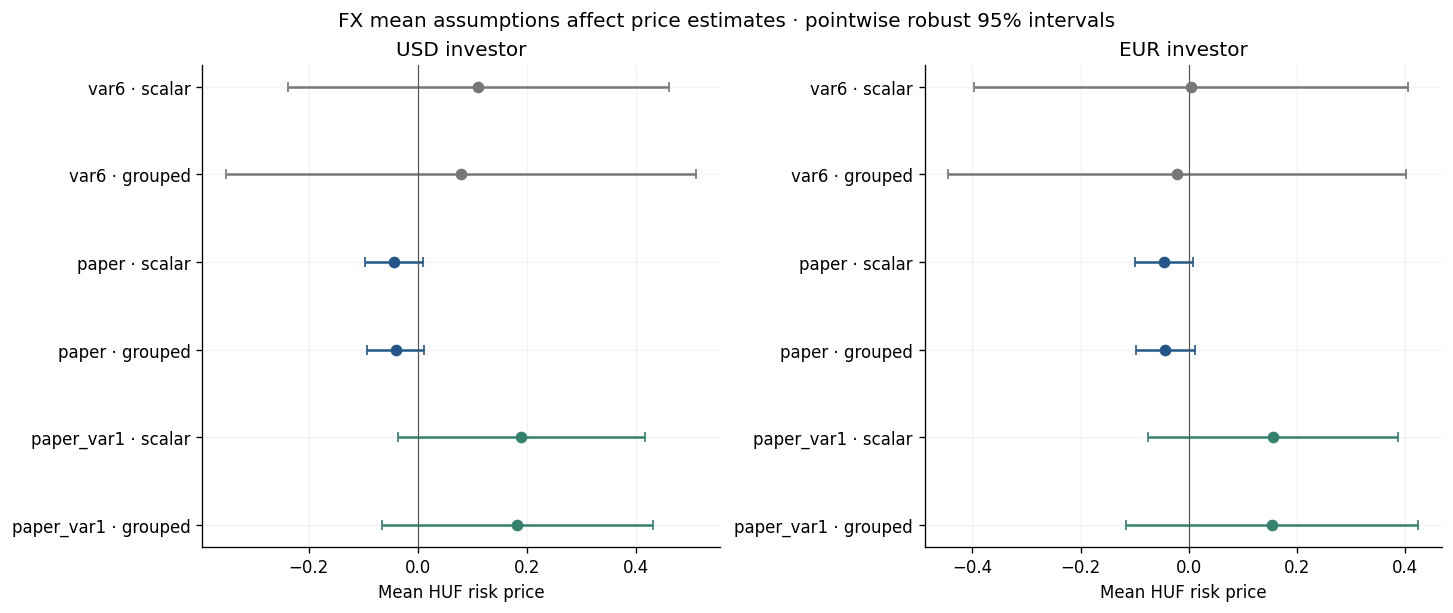

In [5]:
influence_rows=[]
for key,case in fits.items():
    inf=case["inference"]
    if case["variant"]!="full" or not inf["ready"]:continue
    k=model.layout(case["x"],case["pdesign"],case["covariance_model"])[0]
    shifts=np.linalg.solve(inf["Hessian"],case["filter"]["scores"].T).T/len(case["y"])
    relative=np.max(np.abs(shifts[:,:k])/np.sqrt(np.diag(inf["covariance"])[:k]),axis=1)
    for i,month in enumerate(case["dates"]):
        q=quality.loc[(case["currency"],str(month))]
        crisis=("2008-2009" if 2008<=month.year<=2009 else "2020" if month.year==2020 else "2022-2023" if 2022<=month.year<=2023 else "")
        influence_rows.append({"case":key,"month":str(month),"max_price_shift_in_SE":relative[i],"carried_conditioner":bool(q.any()),"crisis_block":crisis})
influence=pd.DataFrame(influence_rows)
if len(influence):
    influence["rank_in_case"]=influence.groupby("case")["max_price_shift_in_SE"].rank(ascending=False,method="min")
    display(influence[influence["carried_conditioner"]].round(4))
    display(influence.sort_values(["case","max_price_shift_in_SE"],ascending=[True,False]).groupby("case").head(3).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
colors={"var6":"#777777","paper":"#235789","paper_var1":"#34816d"}
for ax,currency in zip(axes,["USD","EUR"]):
    rows=main[main["perspective"].eq(currency)]
    labels=[f"{r.mean_model} · {r.covariance}" for r in rows.itertuples()]
    ax.barh(np.arange(len(rows)),rows["AIC_from_best"],color=[colors[m] for m in rows["mean_model"]])
    ax.set(yticks=np.arange(len(rows)),yticklabels=labels,title=f"{currency} · same 321 months",xlabel="AIC above the best main fit")
    ax.invert_yaxis()
plt.savefig(OUT/"01_model_comparison.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()
fig,axes=plt.subplots(1,2,figsize=(12,5),layout="constrained")
for ax,currency in zip(axes,["USD","EUR"]):
    rows=main[main["perspective"].eq(currency)]
    for i,(key,row) in enumerate(rows.iterrows()):
        q=coefficients.loc[(key,"H","intercept")]
        if np.isfinite(q["robust_se"]):ax.errorbar(q["estimate"],i,xerr=1.96*q["robust_se"],fmt="o",color=colors[row["mean_model"]],capsize=3)
        else:ax.plot(q["estimate"],i,marker="x",color="#888888")
    ax.axvline(0,color="#555555",lw=.7)
    ax.set(yticks=np.arange(len(rows)),yticklabels=[f"{r.mean_model} · {r.covariance}" for r in rows.itertuples()],title=f"{currency} investor",xlabel="Mean HUF risk price")
    ax.invert_yaxis()
fig.suptitle("FX mean assumptions affect price estimates · pointwise robust 95% intervals")
plt.savefig(OUT/"02_HUF_price_comparison.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 5. Save the audit and identify the next defensible step

Use the same-window mean/covariance comparisons, the FX-correction test, regularity and residual
screens together. AIC/BIC are descriptive Gaussian-QML criteria; a low value does not validate all
moment restrictions. Influence estimates and persistent-level sensitivities do not establish causal
relationships. All primary estimates use the original fixed return sample; auxiliary windows are labelled.

In [6]:
tables={"main_comparison.csv":main,"all_fit_summary.csv":fit_table,"restriction_tests.csv":tests,
        "price_coefficients.csv":coefficients,"residual_diagnostics.csv":residuals,"cross_covariance_diagnostics.csv":cross_diagnostics,
        "premium_summary.csv":premia,"retired_diagonal_audit.csv":retired,"starting_points.csv":starts_table,"score_influence.csv":influence}
for name,table in tables.items():table.to_csv(OUT/name,float_format="%.17g",lineterminator="\n")
for key,case in fits.items():
    np.savez(OUT/f"parameters_{key}.npz",theta=case["theta"],robust_covariance=case["inference"]["covariance"],
             Hessian=case["inference"]["Hessian"],H=case["filter"]["H"],mu=case["filter"]["mu"],residuals=case["filter"]["errors"])
    case["components"].to_csv(OUT/f"premia_{key}.csv",float_format="%.17g",lineterminator="\n")
    for label,z in case["pdesign"].items():
        pd.DataFrame(z,index=case["dates"],columns=["constant"]+list(case["frames"][label].columns)).to_csv(OUT/f"design_{key}_{label}.csv",float_format="%.17g",lineterminator="\n")
record={"model_version":MODEL_VERSION,"engine_sha256":engine_sha256,"source_snapshot":SNAPSHOT,
    "source_dataset_sha256":manifest["exports"]["dataset.csv"],"upstream":UPSTREAM,"upstream_file_sha256":baseline_hashes,
    "main_first":str(data.index[0]),"main_last":str(data.index[-1]),"main_observations":len(data),
    "mean_models":["var6","paper","paper_var1"],"covariance_models":COVARIANCE_MODELS,
    "grouped_dynamics":model.GROUPS["grouped"],"sensitivity_cases":RUN_SENSITIVITIES,"post_float_start":POST_FLOAT_START,
    "instrument_specification":spec,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,
    "packages":versions,"python":platform.python_version()}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
if hashlib.sha256((source/"dataset.csv").read_bytes()).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset changed.")
display(Markdown("**Main specification audit — fixed five-series sample**"))
display(main[["perspective","mean_model","covariance","parameters","AIC_from_best","BIC_from_best","common_dynamics_p","FX_mean_restriction_p","FX_constancy_p","FX_zero_p","mean_flags","variance_flags","cross_flags","inference_ready"]].round(4))
for currency in ["USD","EUR"]:
    rows=main[main["perspective"].eq(currency)]
    best_aic=rows["AIC"].idxmin();best_bic=rows["BIC"].idxmin()
    display(Markdown(f"**{currency}:** lowest AIC: `{best_aic}`; lowest BIC: `{best_bic}`. "
        f"Numerically regular fits: {int(rows['inference_ready'].sum())}/{len(rows)}. "
        "Read the remaining diagnostic flags before interpreting risk-price tests."))
if "scalar" in COVARIANCE_MODELS:
    display(Markdown("**Interpretation update:** the earlier equity-only VAR adaptation and the paper-style joint "
        "currency-mean model answer different specification questions. Read their risk-price tests separately; "
        "the paper-style results supersede any attempt to treat the earlier high VAR p-values as a replication conclusion."))
    for currency in ["USD","EUR"]:
        pure=f"{currency}_paper_scalar_full";aug=f"{currency}_paper_var1_scalar_full"
        correction=tests.loc[(aug,"Paper FX mean restriction"),"robust_p_value"]
        display(Markdown(f"**{currency} scalar paper-style model:** FX constancy p = **{main.loc[pure,'FX_constancy_p']:.4g}**; "
            f"all FX prices zero p = **{main.loc[pure,'FX_zero_p']:.4g}**. The nested FX correction test gives "
            f"p = **{correction:.3f}**. Remaining variance flags keep these conditional findings provisional."))
    if RUN_SENSITIVITIES:
        aux=[]
        for key,row in fit_table[fit_table["variant"]!="full"].iterrows():
            aux.append({"case":key,"n":row["n"],"FX_constancy_p":tests.loc[(key,"FX prices constant"),"robust_p_value"],
                        "FX_zero_p":tests.loc[(key,"FX prices zero"),"robust_p_value"],"variance_flags":row["variance_flags"]})
        display(Markdown("**Matched sensitivity results** — level-gap p-values remain exploratory; AIC is not compared across windows."))
        display(pd.DataFrame(aux).set_index("case").round(4))
display(Markdown("The paper's currency-mean restriction has now been implemented explicitly and compared with "
    "the VAR adaptation and a nested correction. Grouped dynamics and matched sensitivities provide "
    "a stability audit. Further covariance work may remain; current local prices are still time-constant. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. The frozen dataset and notebook 07 outputs are unchanged."))

**Main specification audit — fixed five-series sample**

,perspective,mean_model,covariance,parameters,AIC_from_best,BIC_from_best,common_dynamics_p,FX_mean_restriction_p,FX_constancy_p,FX_zero_p,mean_flags,variance_flags,cross_flags,inference_ready
case,,,,,,,,,,,,,,
USD_var6_scalar_full,USD,var6,scalar,60,47.7044,145.7618,NaN,NaN,0.3306,0.4424,0,4,2,True
USD_var6_grouped_full,USD,var6,grouped,64,50.3488,163.4920,0.2355,NaN,0.3595,0.4595,0,3,3,True
USD_paper_scalar_full,USD,paper,scalar,34,0.0000,0.0000,NaN,NaN,0.0006,0.0011,0,4,0,True
USD_paper_grouped_full,USD,paper,grouped,38,3.3892,18.4750,0.1774,NaN,0.0021,0.0046,0,2,0,True
USD_paper_var1_scalar_full,USD,paper_var1,scalar,40,4.0335,26.6622,NaN,0.3403,0.0018,0.0011,0,4,1,True
USD_paper_var1_grouped_full,USD,paper_var1,grouped,44,7.4685,45.1829,0.1419,0.3632,0.0030,0.0047,0,2,1,True
EUR_var6_scalar_full,EUR,var6,scalar,60,56.8170,154.8744,NaN,NaN,0.0917,0.1097,0,1,1,True
EUR_var6_grouped_full,EUR,var6,grouped,64,57.3542,170.4975,0.1062,NaN,0.1995,0.1069,0,1,1,True
EUR_paper_scalar_full,EUR,paper,scalar,34,0.0000,0.0000,NaN,NaN,0.0000,0.0000,0,1,0,True


**USD:** lowest AIC: `USD_paper_scalar_full`; lowest BIC: `USD_paper_scalar_full`. Numerically regular fits: 6/6. Read the remaining diagnostic flags before interpreting risk-price tests.

**EUR:** lowest AIC: `EUR_paper_scalar_full`; lowest BIC: `EUR_paper_scalar_full`. Numerically regular fits: 6/6. Read the remaining diagnostic flags before interpreting risk-price tests.

**Interpretation update:** the earlier equity-only VAR adaptation and the paper-style joint currency-mean model answer different specification questions. Read their risk-price tests separately; the paper-style results supersede any attempt to treat the earlier high VAR p-values as a replication conclusion.

**USD scalar paper-style model:** FX constancy p = **0.0005647**; all FX prices zero p = **0.001128**. The nested FX correction test gives p = **0.340**. Remaining variance flags keep these conditional findings provisional.

**EUR scalar paper-style model:** FX constancy p = **8.504e-06**; all FX prices zero p = **2.086e-06**. The nested FX correction test gives p = **0.553**. Remaining variance flags keep these conditional findings provisional.

**Matched sensitivity results** — level-gap p-values remain exploratory; AIC is not compared across windows.

,n,FX_constancy_p,FX_zero_p,variance_flags
case,,,,
USD_paper_scalar_levels,321,0.0006,0.0013,3
EUR_paper_scalar_levels,321,0.0020,0.0007,3
USD_paper_scalar_post_float,223,0.0110,0.0058,2
EUR_paper_scalar_post_float,223,0.0006,0.0011,1


The paper's currency-mean restriction has now been implemented explicitly and compared with the VAR adaptation and a nested correction. Grouped dynamics and matched sensitivities provide a stability audit. Further covariance work may remain; current local prices are still time-constant. Outputs: `output/08_specification_audit/fixed_2026-11-13/2000-01_2026-09/spec_d7a542e8`. The frozen dataset and notebook 07 outputs are unchanged.